# 03: Final Evaluation (Milestone 4)

This notebook completes my CT4101 project. It carries out the next steps from notebook 02 and then makes the single, final evaluation on the held-out test set. The full discussion of these results is in my final report.

1. Setup
2. Fixed model settings and out-of-fold predictions
3. Decision thresholds
4. Calibration check
5. Feature ablation: age and month
6. Final evaluation on the test set
7. Age-group fairness on the test set
8. Permutation importance
9. Conclusion

Sections 2 to 5 use cross-validation on the training set only, and fix every setting and threshold. **The test set is used for the first and only time in section 6**, and nothing after that point changes the model.

The notebook needs `python src/download_data.py` to have been run once, and takes about 3 minutes to run.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import RandomOverSampler
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Make src/ importable whether the notebook is run from the repo root or notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from data import load_raw, prepare_features
from modelling import (
    best_f1_threshold, bootstrap_scores, build_pipeline, cross_fitted_decisions, slice_metrics
)

RANDOM_STATE = 42
N_BOOT = 1000
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#9a9992", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 10,
})
BLUE = "#2a78d6"
GREY = "#7a7972"
COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

In [2]:
# The same split and folds as notebooks 01 and 02, so every result is directly comparable
df = load_raw()
X, y = prepare_features(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_train, y_train))

num_features = X_train.select_dtypes(include="number").columns.tolist()
cat_features = X_train.select_dtypes(exclude="number").columns.tolist()
print("Train:", X_train.shape, " Test:", X_test.shape)

def age_groups(ages):
    return pd.cut(ages, bins=[0, 29, 39, 49, 59, 120],
                  labels=["Under 30", "30-39", "40-49", "50-59", "60+"])

Train: (36168, 15)  Test: (9043, 15)


## 2. Fixed model settings and out-of-fold predictions
Every model is fixed exactly as it was chosen in notebook 02 (`reports/model_comparison.csv`), so I am not re-tuning anything here. I recompute the out-of-fold probabilities on the same folds for use in sections 3 and 4.

In [3]:
# (model with its final settings, sampler or None), as chosen in notebook 02
FINAL_MODELS = {
    "Majority class (baseline)": (DummyClassifier(strategy="most_frequent"), None),
    "Logistic regression (baseline)": (LogisticRegression(max_iter=1000), None),
    "kNN": (KNeighborsClassifier(n_neighbors=151, weights="uniform"),
            RandomOverSampler(random_state=RANDOM_STATE)),
    "Decision tree": (DecisionTreeClassifier(max_depth=20, min_samples_leaf=100,
                                             random_state=RANDOM_STATE), None),
    "Random forest": (RandomForestClassifier(n_estimators=300, max_depth=14, min_samples_leaf=5,
                                             random_state=RANDOM_STATE), None),
    "Gradient boosting": (HistGradientBoostingClassifier(learning_rate=0.03, max_iter=100,
                                                         max_leaf_nodes=31, early_stopping=False,
                                                         random_state=RANDOM_STATE), None),
}
FINAL_MODEL = "Random forest"  # chosen from cross-validation in notebook 02

def make_pipeline(name, num=num_features, cat=cat_features):
    model, sampler = FINAL_MODELS[name]
    return build_pipeline(clone(model), num, cat, clone(sampler) if sampler is not None else None)

oof_proba, cv_rows = {}, []
for name in FINAL_MODELS:
    proba = cross_val_predict(make_pipeline(name), X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=-1)[:, 1]
    oof_proba[name] = proba
    fold_pr = [average_precision_score(y_train.iloc[val], proba[val]) for _, val in folds]
    cv_rows.append({"Model": name, "CV PR-AUC (recomputed)": f"{np.mean(fold_pr):.3f} ± {np.std(fold_pr):.3f}"})

# Check against the table saved by notebook 02
nb02 = pd.read_csv(ROOT / "reports" / "model_comparison.csv").set_index("Model")["PR-AUC"]
check = pd.DataFrame(cv_rows).set_index("Model")
check["Notebook 02"] = nb02
check

,CV PR-AUC (recomputed),Notebook 02
Model,,
Majority class (baseline),0.117 ± 0.000,0.117 ± 0.000
Logistic regression (baseline),0.402 ± 0.008,0.402 ± 0.008
kNN,0.384 ± 0.011,0.384 ± 0.011
Decision tree,0.393 ± 0.008,0.393 ± 0.008
Random forest,0.432 ± 0.014,0.432 ± 0.014
Gradient boosting,0.431 ± 0.010,0.431 ± 0.010


The recomputed scores match notebook 02 to three decimal places for every model, so the fixed settings reproduce its results.

## 3. Decision thresholds
The test set needs one threshold per model, rather than the five per-fold values used in notebook 02. I choose the threshold that maximises F1 on all of the out-of-fold training predictions together. The majority-class baseline keeps 0.5, as it gives every client the same probability.

In [4]:
thresholds = {name: best_f1_threshold(y_train, proba) for name, proba in oof_proba.items()
              if name != "Majority class (baseline)"}
thresholds["Majority class (baseline)"] = 0.5

# For comparison, the per-fold thresholds used in notebook 02
fold_thresholds = {name: cross_fitted_decisions(y_train, oof_proba[name], folds)[1]
                   for name in thresholds if name != "Majority class (baseline)"}
pd.DataFrame({
    "Pooled threshold (used on test)": pd.Series(thresholds),
    "Per-fold thresholds (notebook 02)": pd.Series({k: np.round(v, 3) for k, v in fold_thresholds.items()}),
}).loc[list(FINAL_MODELS)].round(3)

,Pooled threshold (used on test),Per-fold thresholds (notebook 02)
Majority class (baseline),0.500,NaN
Logistic regression (baseline),0.194,"[0.194, 0.184, 0.194, 0.194, 0.18]"
kNN,0.636,"[0.642, 0.636, 0.642, 0.636, 0.649]"
Decision tree,0.248,"[0.282, 0.24, 0.28, 0.248, 0.248]"
Random forest,0.193,"[0.214, 0.179, 0.187, 0.193, 0.179]"
Gradient boosting,0.201,"[0.185, 0.169, 0.2, 0.201, 0.186]"


For every model, the single threshold sits inside the range of its five per-fold values, so it agrees with what each fold chose on its own. kNN has a much higher threshold (0.636) because oversampling pushes its probabilities upwards.

## 4. Calibration check
This checks whether the predicted probabilities can be read as real probabilities, which matters for planning a campaign but not for PR-AUC. Each point on a reliability curve is one tenth of the clients. The Brier score is the mean squared error of the probabilities (lower is better).

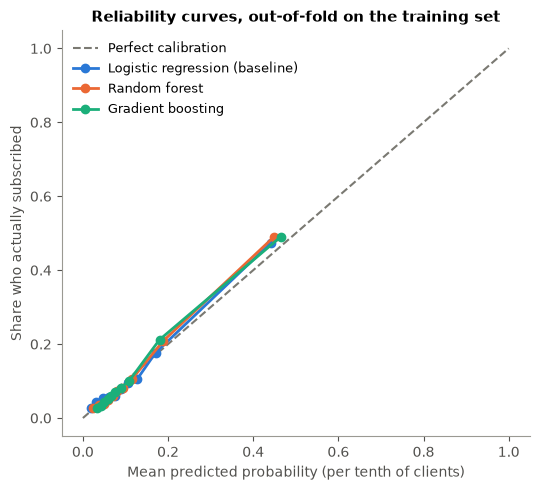

Actual subscription rate: 0.117


,Brier score,Mean predicted probability,Largest bin gap
Model,,,
Logistic regression (baseline),0.0863,0.1170,0.0325
Random forest,0.0834,0.1168,0.0415
Gradient boosting,0.0833,0.1167,0.0319


In [5]:
calib_models = ["Logistic regression (baseline)", "Random forest", "Gradient boosting"]

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1.5, label="Perfect calibration")
rows = []
for colour, name in zip(COLOURS, calib_models):
    frac_pos, mean_pred = calibration_curve(y_train, oof_proba[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", color=colour, linewidth=2, label=name)
    rows.append({"Model": name,
                 "Brier score": brier_score_loss(y_train, oof_proba[name]),
                 "Mean predicted probability": oof_proba[name].mean(),
                 "Largest bin gap": np.abs(frac_pos - mean_pred).max()})
ax.set_xlabel("Mean predicted probability (per tenth of clients)")
ax.set_ylabel("Share who actually subscribed")
ax.set_title("Reliability curves, out-of-fold on the training set")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "calibration_curves.png", dpi=150)
plt.show()

print("Actual subscription rate:", round(y_train.mean(), 3))
pd.DataFrame(rows).set_index("Model").round(4)

All three models are well calibrated. Their mean predicted probability (0.117) matches the actual rate, no tenth of clients is more than 0.042 from the diagonal, and the random forest (Brier score 0.0834) is tied with gradient boosting (0.0833) and slightly ahead of logistic regression (0.0863).

I can conclude that no calibration step is needed, which supports my decision in notebook 02 to handle the imbalance with a threshold rather than resampling.

## 5. Feature ablation: age and month
Notebook 02 found that clients aged 60 and over are flagged far more often than their subscription rate justifies, and that `month` may reflect how the campaigns were run. I will retrain the random forest without `age`, without `month` and without both. I will only change the final model if removing a feature closes most of the age gap at a small cost to PR-AUC.

In [6]:
VARIANTS = {"All features (final model)": [], "Without age": ["age"],
            "Without month": ["month"], "Without age and month": ["age", "month"]}
groups_train = age_groups(X_train["age"])
full_pr = None
rows = []
for variant, dropped in VARIANTS.items():
    num = [c for c in num_features if c not in dropped]
    cat = [c for c in cat_features if c not in dropped]
    proba = cross_val_predict(make_pipeline(FINAL_MODEL, num, cat), X_train.drop(columns=dropped),
                              y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    fold_pr = np.array([average_precision_score(y_train.iloc[val], proba[val]) for _, val in folds])
    full_pr = fold_pr if full_pr is None else full_pr
    decisions, _, fold_f1 = cross_fitted_decisions(y_train, proba, folds)
    by_age = slice_metrics(y_train, decisions, groups_train)
    rows.append({
        "Variant": variant,
        "PR-AUC": f"{fold_pr.mean():.3f} ± {fold_pr.std():.3f}",
        "PR-AUC change (paired)": round((fold_pr - full_pr).mean(), 4),
        "Folds worse": int((fold_pr < full_pr).sum()),
        "F1 tuned": round(fold_f1.mean(), 3),
        "60+ flagged rate": round(by_age.loc["60+", "flagged rate"], 3),
        "60+ false positive rate": round(by_age.loc["60+", "false positive rate"], 3),
        "60+ recall": round(by_age.loc["60+", "recall"], 3),
        "30-59 false positive rate": round(slice_metrics(
            y_train, decisions, groups_train.isin(["30-39", "40-49", "50-59"])).loc[True, "false positive rate"], 3),
    })
print("Actual subscription rate for clients aged 60+:",
      round(y_train[groups_train == "60+"].mean(), 3))
pd.DataFrame(rows).set_index("Variant")

Actual subscription rate for clients aged 60+: 0.337


,PR-AUC,PR-AUC change (paired),Folds worse,F1 tuned,60+ flagged rate,60+ false positive rate,60+ recall,30-59 false positive rate
Variant,,,,,,,,
All features (final model),0.432 ± 0.014,0.0000,0,0.467,0.716,0.616,0.912,0.060
Without age,0.430 ± 0.011,-0.0016,3,0.463,0.533,0.438,0.719,0.054
Without month,0.396 ± 0.015,-0.0360,5,0.414,0.706,0.613,0.889,0.062
Without age and month,0.386 ± 0.013,-0.0455,5,0.402,0.585,0.495,0.760,0.084


Removing `age` costs almost nothing (PR-AUC falls by 0.002 and is lower in three of five folds), but the false positive rate for clients aged 60 and over only falls from 0.616 to 0.438. That is still far above the 0.054 for clients aged 30 to 59, which may indicate that features linked to age, such as being retired or being called in the quieter months, carry most of the same information. Removing `month` costs far more (a fall of 0.036, lower in all five folds) and barely moves the age gap.

I can conclude that removing `age` alone would not make the model fair, and that removing `month` would cost real performance. I will not change the features in the model.

## 6. Final evaluation on the test set
Every model is trained on the full training set with the settings from section 2 and scored once on the 9,043 test clients. I chose the random forest in notebook 02, and that choice stands whatever the test set shows. To show uncertainty, the test rows are resampled 1,000 times. Every model is scored on the same resamples, so the gap between two models has a paired interval.

In [7]:
# The only place in the project where the test set is used to make predictions
final_pipes, test_proba = {}, {}
for name in FINAL_MODELS:
    final_pipes[name] = make_pipeline(name).fit(X_train, y_train)
    test_proba[name] = final_pipes[name].predict_proba(X_test)[:, 1]
test_decisions = {name: (test_proba[name] >= thresholds[name]).astype(int) for name in FINAL_MODELS}

def ci(samples):
    low, high = np.percentile(samples, [2.5, 97.5])
    return f"[{low:.3f}, {high:.3f}]"

boot_pr = {}
rows = []
for name in FINAL_MODELS:
    boot_pr[name] = bootstrap_scores(y_test, test_proba[name], average_precision_score, N_BOOT, RANDOM_STATE)
    boot_f1 = bootstrap_scores(y_test, test_decisions[name], f1_score, N_BOOT, RANDOM_STATE)
    rows.append({
        "Model": name,
        "Test PR-AUC": round(average_precision_score(y_test, test_proba[name]), 3),
        "PR-AUC 95% CI": ci(boot_pr[name]),
        "CV PR-AUC": check.loc[name, "CV PR-AUC (recomputed)"],
        "Test ROC-AUC": round(roc_auc_score(y_test, test_proba[name]), 3),
        "Test F1": round(f1_score(y_test, test_decisions[name]), 3),
        "F1 95% CI": ci(boot_f1),
        "Precision": round(precision_score(y_test, test_decisions[name], zero_division=0), 3),
        "Recall": round(recall_score(y_test, test_decisions[name]), 3),
    })
test_results = pd.DataFrame(rows).set_index("Model")
test_results.to_csv(ROOT / "reports" / "test_results.csv")
test_results

,Test PR-AUC,PR-AUC 95% CI,CV PR-AUC,Test ROC-AUC,Test F1,F1 95% CI,Precision,Recall
Model,,,,,,,,
Majority class (baseline),0.117,"[0.111, 0.123]",0.117 ± 0.000,0.500,0.000,"[0.000, 0.000]",0.000,0.000
Logistic regression (baseline),0.411,"[0.380, 0.446]",0.402 ± 0.008,0.772,0.449,"[0.423, 0.475]",0.448,0.450
kNN,0.393,"[0.362, 0.426]",0.384 ± 0.011,0.767,0.422,"[0.399, 0.447]",0.386,0.467
Decision tree,0.420,"[0.388, 0.451]",0.393 ± 0.008,0.764,0.471,"[0.444, 0.496]",0.456,0.487
Random forest,0.444,"[0.413, 0.476]",0.432 ± 0.014,0.797,0.483,"[0.458, 0.507]",0.443,0.530
Gradient boosting,0.450,"[0.418, 0.484]",0.431 ± 0.010,0.796,0.484,"[0.457, 0.509]",0.456,0.515


In [8]:
# Paired comparisons on identical resamples: the final model against its closest rival and the baseline
for other in ["Gradient boosting", "Logistic regression (baseline)"]:
    gap = boot_pr[FINAL_MODEL] - boot_pr[other]
    point = average_precision_score(y_test, test_proba[FINAL_MODEL]) - average_precision_score(y_test, test_proba[other])
    print(f"{FINAL_MODEL} minus {other}: PR-AUC gap {point:+.3f}, 95% CI {ci(gap)}, "
          f"random forest ahead in {(gap > 0).mean():.0%} of resamples")

Random forest minus Gradient boosting: PR-AUC gap -0.006, 95% CI [-0.016, 0.004], random forest ahead in 10% of resamples
Random forest minus Logistic regression (baseline): PR-AUC gap +0.033, 95% CI [0.019, 0.048], random forest ahead in 100% of resamples


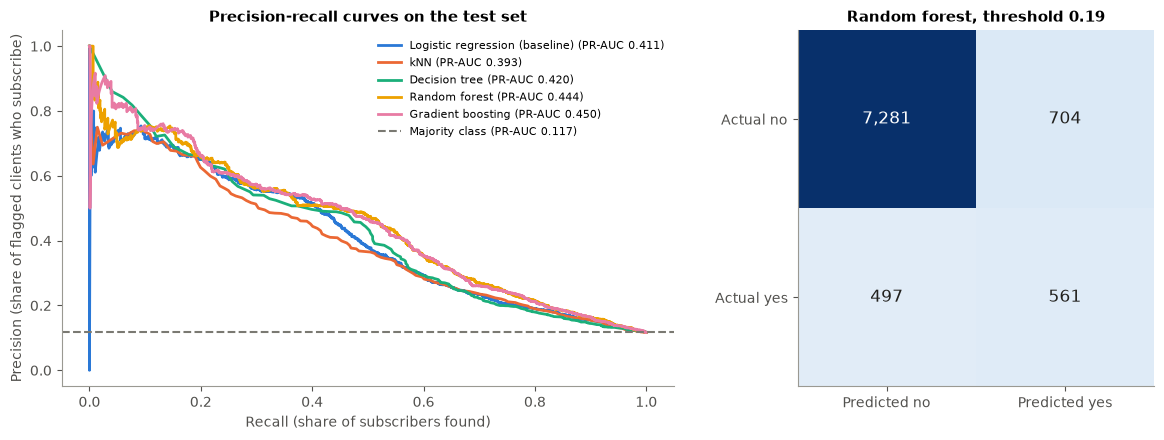

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
for colour, name in zip(COLOURS, [n for n in FINAL_MODELS if n != "Majority class (baseline)"]):
    precision, recall, _ = precision_recall_curve(y_test, test_proba[name])
    ax.plot(recall, precision, color=colour, linewidth=2,
            label=f"{name} (PR-AUC {test_results.loc[name, 'Test PR-AUC']:.3f})")
ax.axhline(y_test.mean(), color=GREY, linestyle="--", linewidth=1.5,
           label=f"Majority class (PR-AUC {y_test.mean():.3f})")
ax.set_xlabel("Recall (share of subscribers found)")
ax.set_ylabel("Precision (share of flagged clients who subscribe)")
ax.set_title("Precision-recall curves on the test set")
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
cm = confusion_matrix(y_test, test_decisions[FINAL_MODEL])
ax.imshow(cm, cmap="Blues", vmin=-cm.max() * 0.05, vmax=cm.max())
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=12,
                color="white" if cm[i, j] > cm.max() / 2 else "#22211e")
ax.set_xticks([0, 1], ["Predicted no", "Predicted yes"])
ax.set_yticks([0, 1], ["Actual no", "Actual yes"])
ax.set_title(f"{FINAL_MODEL}, threshold {thresholds[FINAL_MODEL]:.2f}")
fig.tight_layout()
fig.savefig(FIG_DIR / "test_results.png", dpi=150)
plt.show()

In [10]:
# The call-budget view from notebook 02, now on the test set
ranked = y_test.to_numpy()[np.argsort(-test_proba[FINAL_MODEL])]
rows = []
for share in [0.1, 0.2, 0.3, 0.5]:
    top = ranked[: int(len(ranked) * share)]
    rows.append({"Share of clients called": f"{share:.0%}",
                 "Precision in that group": round(top.mean(), 3),
                 "Share of all subscribers reached": round(top.sum() / ranked.sum(), 3)})
pd.DataFrame(rows).set_index("Share of clients called")

,Precision in that group,Share of all subscribers reached
Share of clients called,,
10%,0.506,0.432
20%,0.351,0.600
30%,0.271,0.696
50%,0.194,0.828


The random forest reaches a test PR-AUC of 0.444 (95% CI 0.413 to 0.476). It beats the logistic regression baseline (0.411) by 0.033 (0.019 to 0.048) and is ahead in all 1,000 resamples, so I can conclude that the improvement is genuine. Gradient boosting scored 0.450, but the gap (-0.016 to 0.004) includes zero, as it did in cross-validation, so the random forest remains my final model.

Every learned model scored slightly higher than in cross-validation, as expected from training on all of the training data, and the ranking barely changed. At the threshold of 0.193 the random forest finds 561 of the 1,058 subscribers (recall 0.530, precision 0.443), and calling the 20% of clients ranked highest would reach 60.0% of all subscribers.

## 7. Age-group fairness on the test set
This checks whether the age-group pattern from notebook 02 holds on the test set. Some groups are small, so I show their sizes and a bootstrap 95% interval for recall and the false positive rate within each group.

In [11]:
groups_test = age_groups(X_test["age"])
age_test = slice_metrics(y_test, test_decisions[FINAL_MODEL], groups_test)

def false_positive_rate(y_true, pred):
    negatives = y_true == 0
    return pred[negatives].mean() if negatives.any() else np.nan

for label, metric in [("recall", recall_score), ("false positive rate", false_positive_rate)]:
    intervals = {}
    for group in age_test.index:
        mask = (groups_test == group).to_numpy()
        intervals[group] = ci(bootstrap_scores(y_test[mask], test_decisions[FINAL_MODEL][mask],
                                               metric, N_BOOT, RANDOM_STATE))
    age_test[f"{label} 95% CI"] = pd.Series(intervals)

age_test[["clients", "subscribers", "actual rate", "flagged rate", "precision",
          "recall", "recall 95% CI", "false positive rate", "false positive rate 95% CI"]].round(3)

,clients,subscribers,actual rate,flagged rate,precision,recall,recall 95% CI,false positive rate,false positive rate 95% CI
group,,,,,,,,,
Under 30,1003,179,0.178,0.269,0.448,0.676,"[0.603, 0.747]",0.181,"[0.157, 0.207]"
30-39,3608,379,0.105,0.112,0.426,0.454,"[0.402, 0.503]",0.072,"[0.063, 0.082]"
40-49,2332,209,0.090,0.078,0.475,0.411,"[0.343, 0.478]",0.045,"[0.036, 0.053]"
50-59,1763,179,0.102,0.095,0.461,0.430,"[0.358, 0.500]",0.057,"[0.046, 0.068]"
60+,337,112,0.332,0.721,0.432,0.938,"[0.887, 0.980]",0.613,"[0.546, 0.677]"


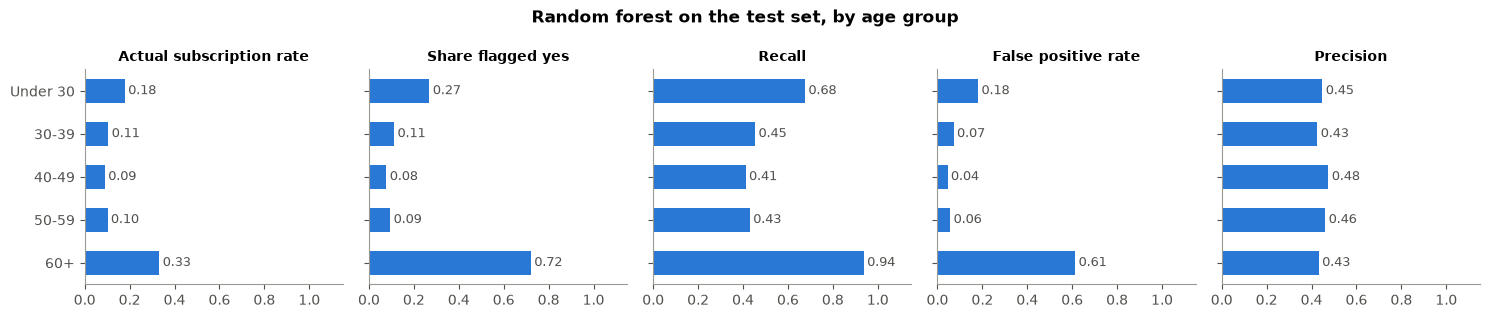

In [12]:
panels = {"actual rate": "Actual subscription rate", "flagged rate": "Share flagged yes",
          "recall": "Recall", "false positive rate": "False positive rate", "precision": "Precision"}
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2), sharey=True, sharex=True)
for ax, (col, title) in zip(axes, panels.items()):
    ax.barh(age_test.index.astype(str), age_test[col], color=BLUE, height=0.55)
    for pos, value in enumerate(age_test[col]):
        ax.text(value + 0.015, pos, f"{value:.2f}", va="center", fontsize=9, color="#52514e")
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, 1.15)
axes[0].invert_yaxis()
fig.suptitle(f"{FINAL_MODEL} on the test set, by age group", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "test_age_fairness.png", dpi=150)
plt.show()

The pattern holds. Precision is fairly even across groups (0.426 to 0.475), but clients aged 60 and over have a false positive rate of 0.613 (0.546 to 0.677), against 0.045 to 0.072 for clients aged 30 to 59. The model flags 72.1% of them, more than twice their actual subscription rate of 33.2%. The intervals are far apart, so the small size of the group (337 clients) does not explain the gap. Clients under 30 show a milder version of the same pattern (0.181).

I can conclude that the model would direct many unsuccessful calls towards older clients, and section 5 showed that removing `age` does not fix this. I will discuss this in my report.

## 8. Permutation importance
Each feature is shuffled in the test set 10 times, and the fall in PR-AUC is measured. The shuffling uses the original columns, so each categorical feature counts as one. Features that share information, such as `poutcome` and `pdays`, can split the credit, and the importance shows what the model uses rather than what causes a client to subscribe.

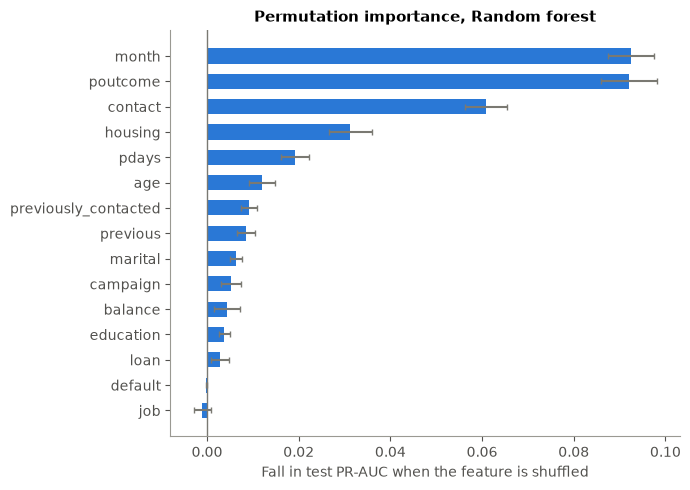

,Mean PR-AUC drop,SD
month,0.0925,0.0050
poutcome,0.0920,0.0061
contact,0.0608,0.0046
housing,0.0313,0.0047
pdays,0.0192,0.0031
age,0.0119,0.0029
previously_contacted,0.0092,0.0017
previous,0.0085,0.0019
marital,0.0063,0.0012
campaign,0.0052,0.0021


In [13]:
perm = permutation_importance(final_pipes[FINAL_MODEL], X_test, y_test, scoring="average_precision",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({"Mean PR-AUC drop": perm.importances_mean,
                           "SD": perm.importances_std}, index=X_test.columns).sort_values("Mean PR-AUC drop")

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importance.index, importance["Mean PR-AUC drop"], xerr=importance["SD"],
        color=BLUE, height=0.6, error_kw={"ecolor": GREY, "capsize": 2})
ax.axvline(0, color=GREY, linewidth=1)
ax.set_xlabel("Fall in test PR-AUC when the feature is shuffled")
ax.set_title(f"Permutation importance, {FINAL_MODEL}")
fig.tight_layout()
fig.savefig(FIG_DIR / "permutation_importance.png", dpi=150)
plt.show()
importance.sort_values("Mean PR-AUC drop", ascending=False).round(4)

The model relies most on `month` (a fall of 0.093) and `poutcome` (0.092), followed by `contact` (0.061) and `housing` (0.031). Two of the top three describe how the bank ran its campaigns rather than the client, which agrees with section 5. `age` has a small importance (0.012), in line with the ablation.

It is worth noting that `job` has an importance of about zero, despite the large differences between jobs in notebook 02. Maybe this indicates that its information is shared with features such as `age` and `education`.

## 9. Conclusion

**Final model.** Random forest with 300 trees, `max_depth=14`, `min_samples_leaf=5` and no resampling, using a decision threshold of 0.193 chosen from the out-of-fold training predictions.

**Evidence.** On the held-out test set it has a PR-AUC of 0.444 (95% CI 0.413 to 0.476), a ROC-AUC of 0.797 and an F1 of 0.483. It beats the logistic regression baseline by 0.033 PR-AUC in every bootstrap resample, and the majority-class baseline (0.117) by a wide margin. Gradient boosting performs the same within the uncertainty of the test set. The probabilities are well calibrated, and the test scores agree with cross-validation, which may indicate that the model selection did not overfit the training folds.

**Limitations.**
- Clients aged 60 and over are flagged at more than twice their subscription rate. Removing `age` reduces this but does not remove it, as other features stand in for age.
- The model depends heavily on `month` and `contact`, which reflect how the 2008 to 2010 campaigns were run. A random split cannot show how well the model would transfer to a future campaign.
- Recall is lowest for clients with no previous campaign history, who make up most of the missed subscribers (notebook 02).
- The threshold maximises F1, which treats a missed subscriber and an unnecessary call as equally costly. A bank would set it from its own costs.

**Recommendation.** I do not believe this model should be used to decide automatically whom to call. I propose a limited pilot in which the model ranks clients for a call list, which is where its strength lies, with staff reviewing the calls to clients aged 60 and over and the results monitored by age group and by month. Wider use should depend on the pilot showing that the model holds up on a new campaign and that older clients are not placed under unwanted sales pressure.

Thank you for reading. The final report brings these results together with the decisions made across all three notebooks.